# Bank Marketing: Term-Deposit Prediction
Predict subscription before a call; compare models with chronological validation and average precision.


# Setup


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
DATA_PATH = Path("data/raw/bank-additional/bank-additional-full.csv")
df = pd.read_csv(DATA_PATH, sep=";")

TARGET = "y"
numeric_features = df.select_dtypes(include="number").columns.tolist()
categorical_features = [c for c in df.select_dtypes(exclude="number").columns if c != TARGET]


# EDA


In [2]:
print(f"Rows: {len(df):,}")
print(f"Columns including target: {df.shape[1]}")
print(f"Memory use: {df.memory_usage(deep=True).sum() / 1024**2:.1f} MB")
print(f"Duplicate rows: {df.duplicated().sum():,}")
display(df.head())
display(df.sample(5, random_state=42))


Rows: 41,188
Columns including target: 21
Memory use: 26.8 MB
Duplicate rows: 12


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
32884,57,technician,married,high.school,no,no,yes,cellular,may,mon,...,1,999,1,failure,-1.8,92.893,-46.2,1.299,5099.1,no
3169,55,unknown,married,unknown,unknown,yes,no,telephone,may,thu,...,2,999,0,nonexistent,1.1,93.994,-36.4,4.860,5191.0,no
32206,33,blue-collar,married,basic.9y,no,no,no,cellular,may,fri,...,1,999,1,failure,-1.8,92.893,-46.2,1.313,5099.1,no
9403,36,admin.,married,high.school,no,no,no,telephone,jun,fri,...,4,999,0,nonexistent,1.4,94.465,-41.8,4.967,5228.1,no
14020,27,housemaid,married,high.school,no,yes,no,cellular,jul,fri,...,2,999,0,nonexistent,1.4,93.918,-42.7,4.963,5228.1,no


In [3]:
schema = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "unique_values": df.nunique(dropna=False),
    "missing": df.isna().sum(),
    "unknown": df.astype("string").eq("unknown").sum(),
})
display(schema)
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)


,dtype,unique_values,missing,unknown
age,int64,78,0,0
job,object,12,0,330
marital,object,4,0,80
education,object,8,0,1731
default,object,3,0,8597
housing,object,3,0,990
loan,object,3,0,990
contact,object,2,0,0
month,object,10,0,0
day_of_week,object,5,0,0


Numeric features: ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


,count,share
y,,
no,36548,0.887346
yes,4640,0.112654


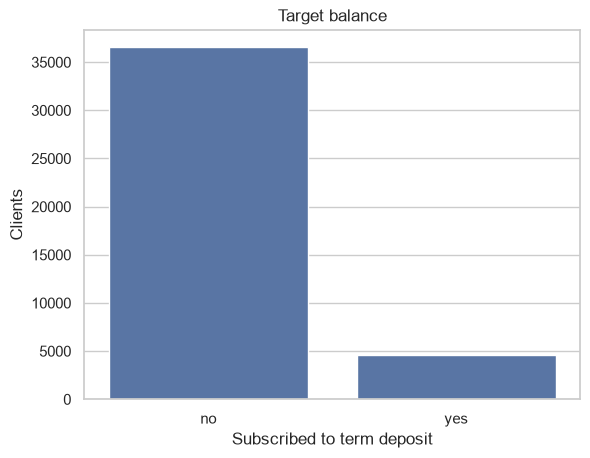

In [4]:
target_counts = df[TARGET].value_counts().rename_axis(TARGET).to_frame("count")
target_counts["share"] = df[TARGET].value_counts(normalize=True)
display(target_counts)

ax = sns.countplot(data=df, x=TARGET, order=target_counts.index)
ax.set(title="Target balance", xlabel="Subscribed to term deposit", ylabel="Clients")
plt.show()


Numeric feature summaries


,count,mean,std,min,1%,25%,50%,75%,99%,max
age,41188.0,40.024060,10.421250,17.000,23.00000,32.000,38.000,47.000,71.000,98.000
duration,41188.0,258.285010,259.279249,0.000,11.00000,102.000,180.000,319.000,1271.130,4918.000
campaign,41188.0,2.567593,2.770014,1.000,1.00000,1.000,2.000,3.000,14.000,56.000
pdays,41188.0,962.475454,186.910907,0.000,3.00000,999.000,999.000,999.000,999.000,999.000
previous,41188.0,0.172963,0.494901,0.000,0.00000,0.000,0.000,0.000,2.000,7.000
emp.var.rate,41188.0,0.081886,1.570960,-3.400,-3.40000,-1.800,1.100,1.400,1.400,1.400
cons.price.idx,41188.0,93.575664,0.578840,92.201,92.20100,93.075,93.749,93.994,94.465,94.767
cons.conf.idx,41188.0,-40.502600,4.628198,-50.800,-49.50000,-42.700,-41.800,-36.400,-26.900,-26.900
euribor3m,41188.0,3.621291,1.734447,0.634,0.65848,1.344,4.857,4.961,4.968,5.045
nr.employed,41188.0,5167.035911,72.251528,4963.600,4963.60000,5099.100,5191.000,5228.100,5228.100,5228.100


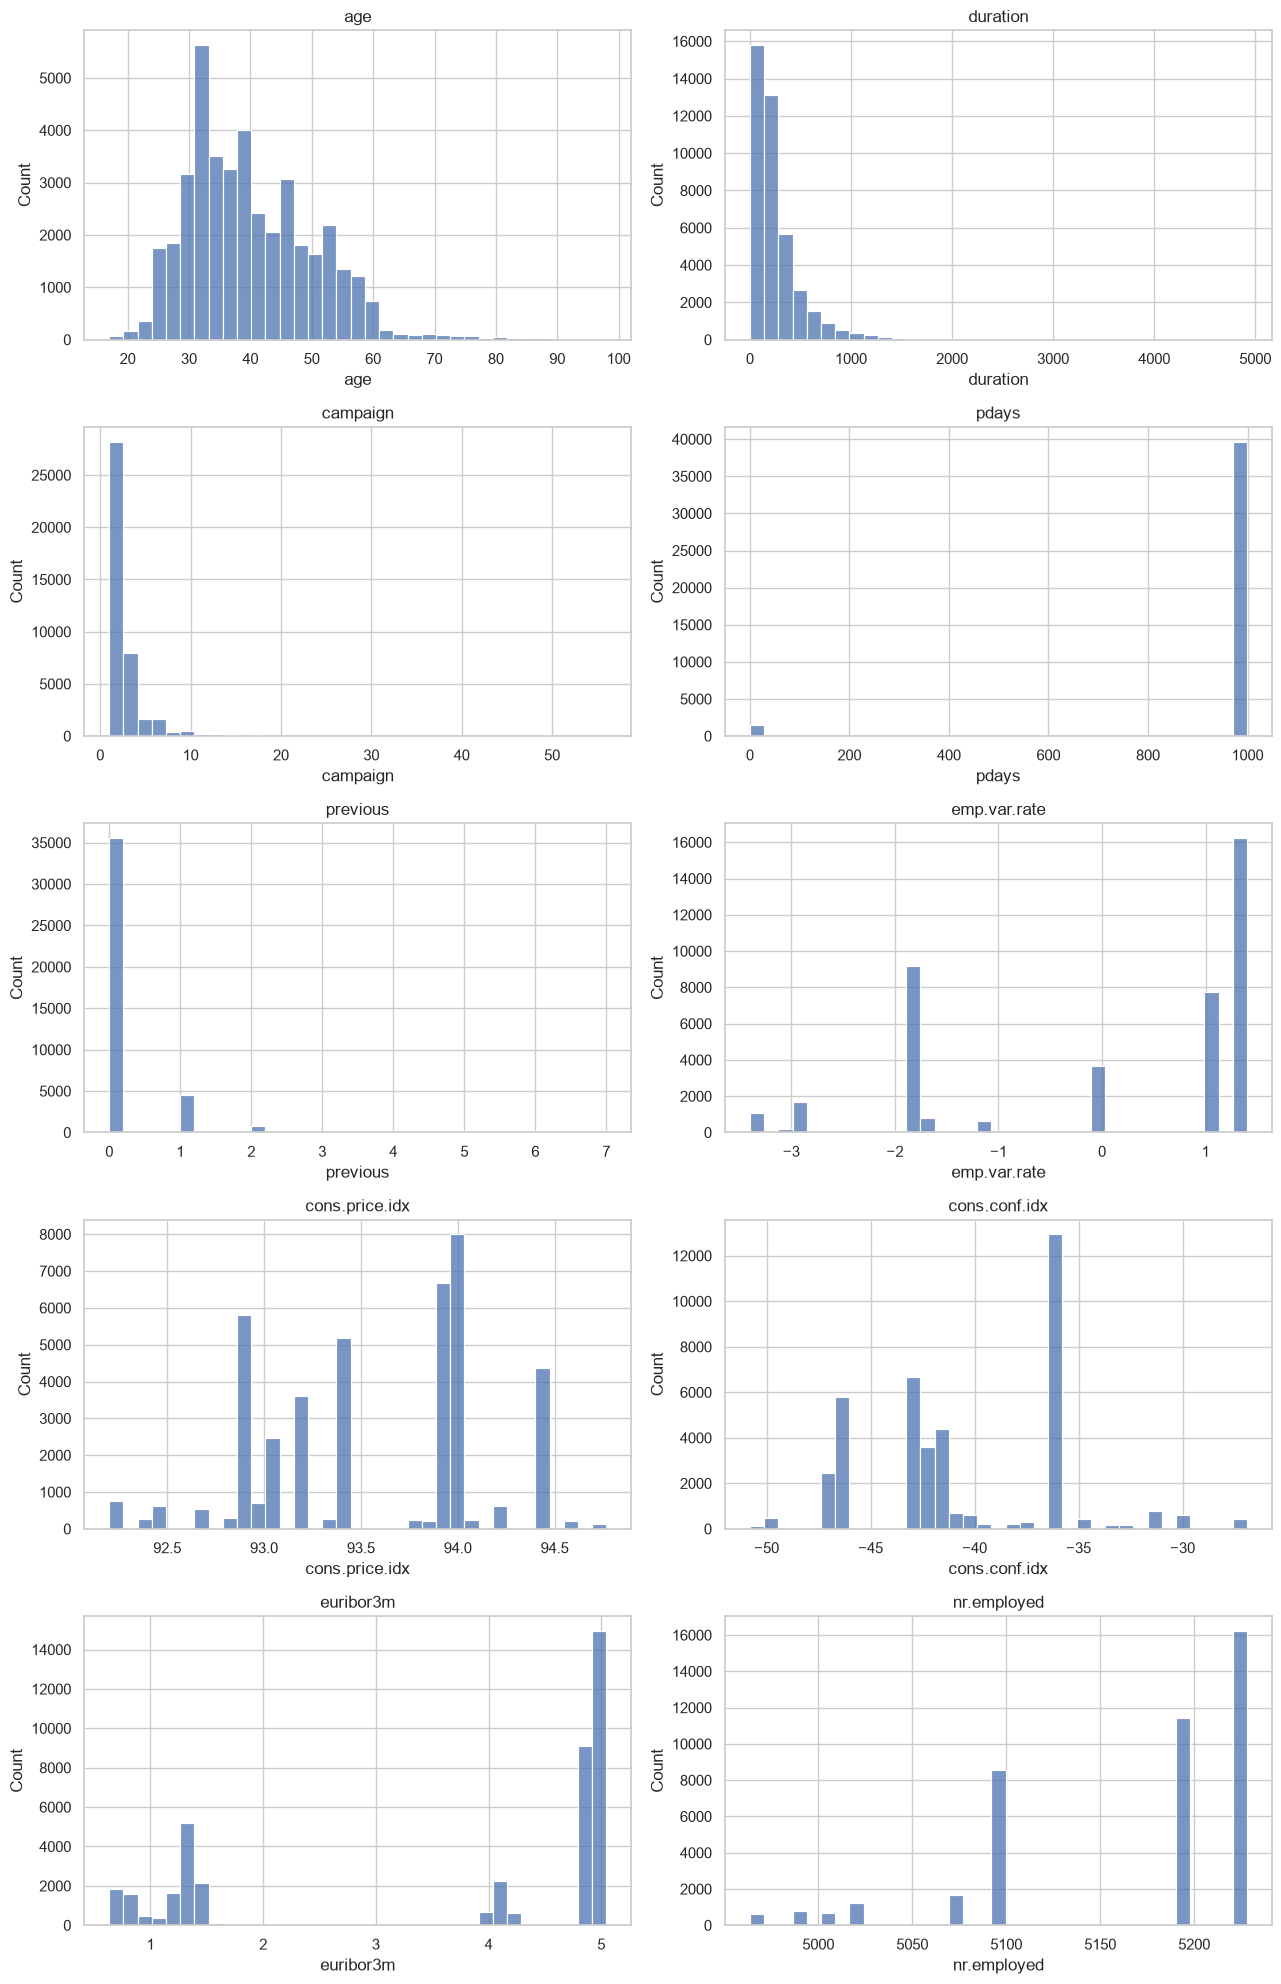

In [5]:
print("Numeric feature summaries")
display(df[numeric_features].describe(percentiles=[.01, .25, .5, .75, .99]).T)

ncols = 2
nrows = (len(numeric_features) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(13, 4 * nrows))
for column, ax in zip(numeric_features, axes.flat):
    sns.histplot(data=df, x=column, bins=35, ax=ax)
    ax.set_title(column)
for ax in axes.flat[len(numeric_features):]:
    ax.remove()
plt.tight_layout()
plt.show()


In [6]:
category_counts = pd.concat({column: df[column].value_counts(dropna=False) for column in categorical_features}, names=['feature', 'category']).rename('clients').reset_index()
display(category_counts)


,feature,category,clients
0,job,admin.,10422
1,job,blue-collar,9254
2,job,technician,6743
3,job,services,3969
4,job,management,2924
5,job,retired,1720
6,job,entrepreneur,1456
7,job,self-employed,1421
8,job,housemaid,1060
9,job,unemployed,1014


In [7]:
category_rates = (df.assign(subscribed=df[TARGET].eq('yes'))
    .melt(id_vars='subscribed', value_vars=categorical_features, var_name='feature', value_name='category')
    .groupby(['feature', 'category'], dropna=False, observed=False)['subscribed']
    .agg(clients='size', subscription_rate='mean').reset_index()
    .sort_values(['feature', 'subscription_rate'], ascending=[True, False]))
display(category_rates)


,feature,category,clients,subscription_rate
0,contact,cellular,26144,0.147376
1,contact,telephone,15044,0.052313
4,day_of_week,thu,8623,0.121188
5,day_of_week,tue,8090,0.117800
6,day_of_week,wed,8134,0.116671
2,day_of_week,fri,7827,0.108087
3,day_of_week,mon,8514,0.099483
7,default,no,32588,0.128790
8,default,unknown,8597,0.051530
9,default,yes,3,0.000000


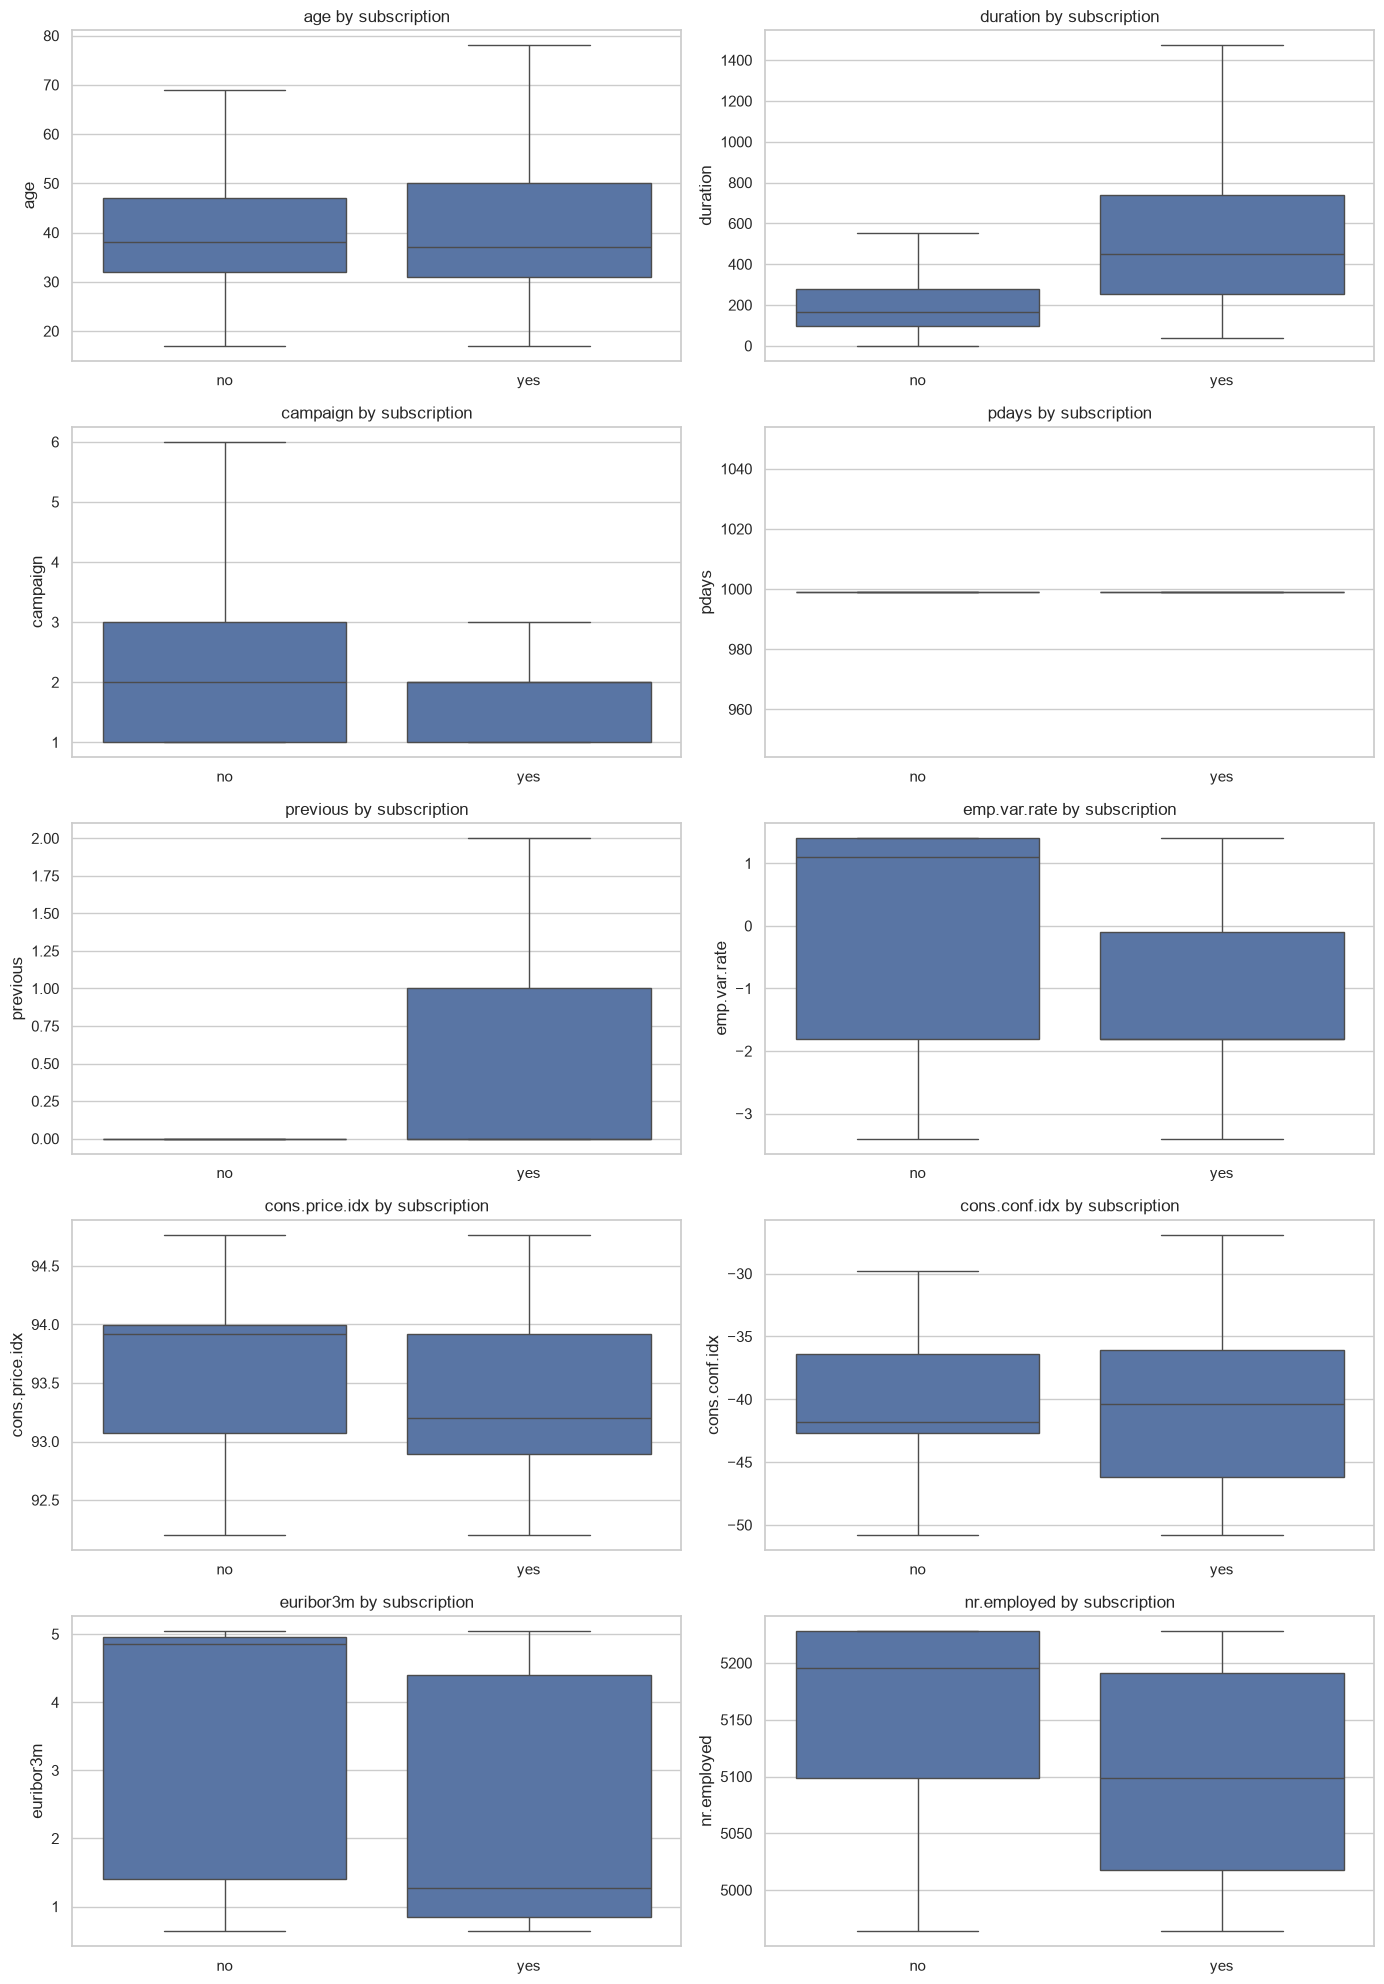

Numeric correlations (descriptive only)


,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
age,1.00,-0.00,0.00,-0.03,0.02,-0.00,0.00,0.13,0.01,-0.02
duration,-0.00,1.00,-0.07,-0.05,0.02,-0.03,0.01,-0.01,-0.03,-0.04
campaign,0.00,-0.07,1.00,0.05,-0.08,0.15,0.13,-0.01,0.14,0.14
pdays,-0.03,-0.05,0.05,1.00,-0.59,0.27,0.08,-0.09,0.30,0.37
previous,0.02,0.02,-0.08,-0.59,1.00,-0.42,-0.20,-0.05,-0.45,-0.50
emp.var.rate,-0.00,-0.03,0.15,0.27,-0.42,1.00,0.78,0.20,0.97,0.91
cons.price.idx,0.00,0.01,0.13,0.08,-0.20,0.78,1.00,0.06,0.69,0.52
cons.conf.idx,0.13,-0.01,-0.01,-0.09,-0.05,0.20,0.06,1.00,0.28,0.10
euribor3m,0.01,-0.03,0.14,0.30,-0.45,0.97,0.69,0.28,1.00,0.95
nr.employed,-0.02,-0.04,0.14,0.37,-0.50,0.91,0.52,0.10,0.95,1.00


In [8]:
fig, axes = plt.subplots(5, 2, figsize=(14, 20))
for column, ax in zip(numeric_features, axes.flat):
    sns.boxplot(data=df, x=TARGET, y=column, ax=ax, showfliers=False)
    ax.set_title(f"{column} by subscription")
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

print("Numeric correlations (descriptive only)")
display(df[numeric_features].corr().round(2))


In [9]:
# Check special values.
print("Duration by outcome (duration is measured during the call):")
display(df.groupby(TARGET)["duration"].describe().round(1))

print("Previous-contact information:")
display(df.groupby("pdays").agg(clients=(TARGET, "size"), subscription_rate=(TARGET, lambda s: s.eq("yes").mean())).sort_values("clients", ascending=False).head(10))

print("Unknown-category share by column:")
unknown_share = df[categorical_features].eq("unknown").mean().sort_values(ascending=False)
display(unknown_share.rename("share_unknown").to_frame())


Duration by outcome (duration is measured during the call):


,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
no,36548.0,220.8,207.1,0.0,95.0,163.5,279.0,4918.0
yes,4640.0,553.2,401.2,37.0,253.0,449.0,741.2,4199.0


Previous-contact information:


,clients,subscription_rate
pdays,,
999,39673,0.092582
3,439,0.678815
6,412,0.701456
4,118,0.533898
9,64,0.546875
2,61,0.606557
7,60,0.666667
12,58,0.448276
10,52,0.576923


Unknown-category share by column:


,share_unknown
default,0.208726
education,0.042027
housing,0.024036
loan,0.024036
job,0.008012
marital,0.001942
contact,0.000000
month,0.000000
day_of_week,0.000000
poutcome,0.000000


# Preprocessing and feature engineering


In [2]:
# Target-independent features.
df_model = df.copy()
df_model["pdays_never_contacted"] = df_model["pdays"].eq(999).astype("int8")
df_model["pdays"] = df_model["pdays"].mask(df_model["pdays"].eq(999), 0)
df_model["campaign"] = np.log1p(df_model["campaign"])
df_model["previous"] = np.log1p(df_model["previous"])

# Duration is post-call; exclude it.
X = df_model.drop(columns=["y", "duration"])
y = df_model["y"].eq("yes").astype("int8")

train_end = int(len(df_model) * 0.70)
valid_end = int(len(df_model) * 0.85)
X_train, X_valid, X_test = X.iloc[:train_end].copy(), X.iloc[train_end:valid_end].copy(), X.iloc[valid_end:].copy()
y_train, y_valid, y_test = y.iloc[:train_end].copy(), y.iloc[train_end:valid_end].copy(), y.iloc[valid_end:].copy()

split_summary = pd.DataFrame({
    "rows": [len(y_train), len(y_valid), len(y_test)],
    "subscription_rate": [y_train.mean(), y_valid.mean(), y_test.mean()],
}, index=["train (earliest)", "validation", "test (latest)"])
display(split_summary)
print(f"Training subscribers: {y_train.sum():,}")
print("The target rate shifts across time blocks; use validation for model decisions and reserve the latest test block for a final future-period check.")
assert "duration" not in X_train.columns
assert len(X_train) + len(X_valid) + len(X_test) == len(df)


,rows,subscription_rate
train (earliest),28831,0.055704
validation,6178,0.106507
test (latest),6179,0.384528


Training subscribers: 1,606
The target rate shifts across time blocks; use validation for model decisions and reserve the latest test block for a final future-period check.


In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = X_train.select_dtypes(exclude="number").columns.tolist()

preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_features),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])

# Fit on train; reuse on later blocks.
X_train_ready = preprocessor.fit_transform(X_train)
X_valid_ready = preprocessor.transform(X_valid)
X_test_ready = preprocessor.transform(X_test)

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Prepared matrix shapes:", X_train_ready.shape, X_valid_ready.shape, X_test_ready.shape)
print("The `unknown` category is kept; the `pdays=999` sentinel is represented by a separate indicator.")
assert X_train_ready.shape[0] == len(y_train)
assert X_valid_ready.shape[0] == len(y_valid)
assert X_test_ready.shape[0] == len(y_test)


Numeric features: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'pdays_never_contacted']
Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
Prepared matrix shapes: (28831, 62) (6178, 62) (6179, 62)
The `unknown` category is kept; the `pdays=999` sentinel is represented by a separate indicator.


# Mutual information


In [12]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import OrdinalEncoder

# Training-only MI; category codes are not model inputs.
mi_categories = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1).fit_transform(X_train[categorical_features])
mi_values = np.column_stack([X_train[numeric_features].to_numpy(), mi_categories])
mi_feature_names = numeric_features + categorical_features
count_features = {"pdays", "pdays_never_contacted"}
mi_is_discrete = [column in count_features for column in numeric_features] + [True] * len(categorical_features)
mi_scores = mutual_info_classif(
    mi_values, y_train, discrete_features=mi_is_discrete, random_state=42
)
mi_ranking = pd.Series(mi_scores, index=mi_feature_names, name="mutual_information").sort_values(ascending=False)
display(mi_ranking.to_frame())
print("MI ranks association, not usefulness.")


,mutual_information
euribor3m,0.014546
cons.price.idx,0.014527
cons.conf.idx,0.013474
month,0.013381
emp.var.rate,0.012176
nr.employed,0.011025
age,0.003438
contact,0.002125
previous,0.001473
job,0.000999


MI ranks association, not usefulness.


# First models


In [4]:
from time import perf_counter
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_score, recall_score
from sklearn.tree import DecisionTreeClassifier

# Practice sequence: Logistic Regression, Decision Tree, Random Forest, HistGradientBoosting.
models = {
    "Prior baseline": DummyClassifier(strategy="prior"),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, min_samples_leaf=50, random_state=42),
}

fitted_models = {}
model_results = []
for name, model in models.items():
    started = perf_counter()
    model.fit(X_train_ready, y_train)
    fit_seconds = perf_counter() - started
    train_probability = model.predict_proba(X_train_ready)[:, 1]
    valid_probability = model.predict_proba(X_valid_ready)[:, 1]
    # Reference threshold only.
    valid_prediction = valid_probability >= 0.5
    fitted_models[name] = model
    model_results.append({
        "model": name,
        "train_PR_AUC": average_precision_score(y_train, train_probability),
        "validation_PR_AUC": average_precision_score(y_valid, valid_probability),
        "validation_precision_at_0.5": precision_score(y_valid, valid_prediction, zero_division=0),
        "validation_recall_at_0.5": recall_score(y_valid, valid_prediction, zero_division=0),
        "fit_seconds": fit_seconds,
    })

model_results = pd.DataFrame(model_results).sort_values("validation_PR_AUC", ascending=False)
display(model_results)


,model,train_PR_AUC,validation_PR_AUC,validation_precision_at_0.5,validation_recall_at_0.5,fit_seconds
1,Logistic Regression,0.174571,0.197705,0.0,0.0,0.015284
2,Decision Tree,0.155673,0.139135,0.0,0.0,0.036577
0,Prior baseline,0.055704,0.106507,0.0,0.0,0.000475


In [14]:
threshold_rows = []
for name in ["Logistic Regression", "Decision Tree"]:
    probability = fitted_models[name].predict_proba(X_valid_ready)[:, 1]
    for threshold in [0.05, 0.10, 0.15, 0.20, 0.30, 0.50]:
        prediction = probability >= threshold
        threshold_rows.append({
            "model": name,
            "threshold": threshold,
            "clients_flagged": int(prediction.sum()),
            "share_flagged": prediction.mean(),
            "precision": precision_score(y_valid, prediction, zero_division=0),
            "recall": recall_score(y_valid, prediction, zero_division=0),
        })

display(pd.DataFrame(threshold_rows))


,model,threshold,clients_flagged,share_flagged,precision,recall
0,Logistic Regression,0.05,5854,0.947556,0.110181,0.980243
1,Logistic Regression,0.10,2697,0.436549,0.152021,0.623100
2,Logistic Regression,0.15,970,0.157009,0.232990,0.343465
3,Logistic Regression,0.20,210,0.033992,0.304762,0.097264
4,Logistic Regression,0.30,4,0.000647,0.250000,0.001520
5,Logistic Regression,0.50,0,0.000000,0.000000,0.000000
6,Decision Tree,0.05,6178,1.000000,0.106507,1.000000
7,Decision Tree,0.10,2859,0.462771,0.124169,0.539514
8,Decision Tree,0.15,2092,0.338621,0.148184,0.471125
9,Decision Tree,0.20,2092,0.338621,0.148184,0.471125


# Optuna tuning


In [15]:
import optuna
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.pipeline import Pipeline

optuna.logging.set_verbosity(optuna.logging.WARNING)
time_cv = TimeSeriesSplit(n_splits=3)
N_TRIALS = 20  # 20 trials, 3 forward-in-time folds


In [16]:
def objective_rf(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 150, 500, step=50),
        "max_depth": trial.suggest_categorical("max_depth", [None, 6, 10, 14, 20]),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 30),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 30, log=True),
        "max_features": trial.suggest_float("max_features", 0.3, 1.0),
        "class_weight": trial.suggest_categorical("class_weight", [None, "balanced", "balanced_subsample"]),
    }
    pipeline = Pipeline([
        ("preprocess", preprocessor),
        ("model", RandomForestClassifier(**params, random_state=42, n_jobs=-1)),
    ])
    scores = cross_val_score(pipeline, X_train, y_train, cv=time_cv, scoring="average_precision", n_jobs=1)
    trial.set_user_attr("fold_scores", scores.tolist())
    return scores.mean()

study_rf = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42))
study_rf.optimize(objective_rf, n_trials=N_TRIALS)
print(f"Best Random Forest time-CV average precision: {study_rf.best_value:.4f}")
print("Best parameters:", study_rf.best_params)

rf_model = Pipeline([
    ("preprocess", preprocessor),
    ("model", RandomForestClassifier(**study_rf.best_params, random_state=42, n_jobs=-1)),
])
rf_model.fit(X_train, y_train)
rf_valid_probability = rf_model.predict_proba(X_valid)[:, 1]
rf_valid_ap = average_precision_score(y_valid, rf_valid_probability)
print(f"Random Forest validation average precision: {rf_valid_ap:.4f}")


Best Random Forest time-CV average precision: 0.0786
Best parameters: {'n_estimators': 200, 'max_depth': 6, 'min_samples_split': 20, 'min_samples_leaf': 4, 'max_features': 0.6705670253913791, 'class_weight': None}


Random Forest validation average precision: 0.1634


In [17]:
# Dense one-hot output is required by HistGradientBoostingClassifier.
hgb_preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_features),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
], sparse_threshold=0.0)

def objective_hgb(trial):
    params = {
        "max_iter": trial.suggest_int("max_iter", 100, 400, step=50),
        "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.2, log=True),
        "max_leaf_nodes": trial.suggest_int("max_leaf_nodes", 7, 63, step=8),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 10, 100),
        "l2_regularization": trial.suggest_float("l2_regularization", 1e-4, 10.0, log=True),
        "max_features": trial.suggest_float("max_features", 0.5, 1.0),
        "class_weight": trial.suggest_categorical("class_weight", [None, "balanced"]),
    }
    pipeline = Pipeline([
        ("preprocess", hgb_preprocessor),
        ("model", HistGradientBoostingClassifier(**params, early_stopping=False, random_state=42)),
    ])
    scores = cross_val_score(pipeline, X_train, y_train, cv=time_cv, scoring="average_precision", n_jobs=1)
    trial.set_user_attr("fold_scores", scores.tolist())
    return scores.mean()

study_hgb = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=43))
study_hgb.optimize(objective_hgb, n_trials=N_TRIALS)
print(f"Best HistGradientBoosting time-CV average precision: {study_hgb.best_value:.4f}")
print("Best parameters:", study_hgb.best_params)

hgb_model = Pipeline([
    ("preprocess", hgb_preprocessor),
    ("model", HistGradientBoostingClassifier(**study_hgb.best_params, early_stopping=False, random_state=42)),
])
hgb_model.fit(X_train, y_train)
hgb_valid_probability = hgb_model.predict_proba(X_valid)[:, 1]
hgb_valid_ap = average_precision_score(y_valid, hgb_valid_probability)
print(f"HistGradientBoosting validation average precision: {hgb_valid_ap:.4f}")


Best HistGradientBoosting time-CV average precision: 0.0694
Best parameters: {'max_iter': 100, 'learning_rate': 0.03877569451158769, 'max_leaf_nodes': 7, 'min_samples_leaf': 36, 'l2_regularization': 0.0009592604933543358, 'max_features': 0.99903176806731, 'class_weight': None}


HistGradientBoosting validation average precision: 0.1544


In [18]:
advanced_results = pd.DataFrame([
    {"model": "Random Forest (Optuna)", "time_CV_average_precision": study_rf.best_value, "validation_average_precision": rf_valid_ap},
    {"model": "HistGradientBoosting (Optuna)", "time_CV_average_precision": study_hgb.best_value, "validation_average_precision": hgb_valid_ap},
])
display(advanced_results.sort_values("validation_average_precision", ascending=False))


,model,time_CV_average_precision,validation_average_precision
0,Random Forest (Optuna),0.078625,0.163398
1,HistGradientBoosting (Optuna),0.069445,0.154394


# CatBoost tuning


In [19]:
from catboost import CatBoostClassifier


def objective_catboost(trial):
    params = {
        "iterations": trial.suggest_int("iterations", 300, 800, step=100),
        "depth": trial.suggest_int("depth", 4, 9),
        "learning_rate": trial.suggest_float("learning_rate", 0.02, 0.2, log=True),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 0.1, 20.0, log=True),
        "random_strength": trial.suggest_float("random_strength", 0.0, 2.0),
        "bagging_temperature": trial.suggest_float("bagging_temperature", 0.0, 5.0),
        "auto_class_weights": trial.suggest_categorical("auto_class_weights", [None, "Balanced", "SqrtBalanced"]),
    }
    fold_scores = []
    for fit_idx, score_idx in time_cv.split(X_train):
        model = CatBoostClassifier(
            **params, random_seed=42, verbose=False,
            allow_writing_files=False, thread_count=-1,
        )
        model.fit(
            X_train.iloc[fit_idx], y_train.iloc[fit_idx],
            cat_features=categorical_features,
        )
        probability = model.predict_proba(X_train.iloc[score_idx])[:, 1]
        fold_scores.append(average_precision_score(y_train.iloc[score_idx], probability))
    trial.set_user_attr("fold_scores", fold_scores)
    return float(np.mean(fold_scores))

study_catboost = optuna.create_study(
    direction="maximize", sampler=optuna.samplers.TPESampler(seed=44)
)
study_catboost.optimize(objective_catboost, n_trials=N_TRIALS)
print(f"Best CatBoost time-CV average precision: {study_catboost.best_value:.4f}")
print("Fold scores:", study_catboost.best_trial.user_attrs["fold_scores"])
print("Best parameters:", study_catboost.best_params)


Best CatBoost time-CV average precision: 0.0985
Fold scores: [0.04958336099354896, 0.06402645613432226, 0.1818344625079066]
Best parameters: {'iterations': 400, 'depth': 6, 'learning_rate': 0.02529266856382233, 'l2_leaf_reg': 5.72666136474444, 'random_strength': 0.14147010812714156, 'bagging_temperature': 2.710152111752527, 'auto_class_weights': None}


In [20]:
catboost_model = CatBoostClassifier(
    **study_catboost.best_params,
    random_seed=42,
    verbose=False,
    allow_writing_files=False,
    thread_count=-1,
)
catboost_model.fit(X_train, y_train, cat_features=categorical_features)
catboost_valid_probability = catboost_model.predict_proba(X_valid)[:, 1]
catboost_valid_ap = average_precision_score(y_valid, catboost_valid_probability)
print(f"CatBoost validation average precision: {catboost_valid_ap:.4f}")

all_validation_scores = pd.concat([
    model_results[["model", "validation_PR_AUC"]].rename(columns={"validation_PR_AUC": "validation_average_precision"}),
    advanced_results[["model", "validation_average_precision"]],
    pd.DataFrame([{"model": "CatBoost (Optuna)", "validation_average_precision": catboost_valid_ap}]),
], ignore_index=True)
display(all_validation_scores.sort_values("validation_average_precision", ascending=False))


CatBoost validation average precision: 0.1362


,model,validation_average_precision
0,Logistic Regression,0.197705
3,Random Forest (Optuna),0.163398
4,HistGradientBoosting (Optuna),0.154394
1,Decision Tree,0.139135
5,CatBoost (Optuna),0.136185
2,Prior baseline,0.106507


# Logistic Regression tuning


In [21]:
def objective_logistic(trial):
    params = {
        'C': trial.suggest_float('C', 1e-3, 1e3, log=True),
        'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced']),
    }
    pipeline = Pipeline([('preprocess', preprocessor), ('model', LogisticRegression(**params, max_iter=2000, random_state=42))])
    scores = cross_val_score(pipeline, X_train, y_train, cv=time_cv, scoring='average_precision', n_jobs=1)
    trial.set_user_attr('fold_scores', scores.tolist())
    return scores.mean()

study_logistic = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=45))
study_logistic.optimize(objective_logistic, n_trials=N_TRIALS)
print(f'Best Logistic Regression time-CV average precision: {study_logistic.best_value:.4f}')
print('Fold scores:', study_logistic.best_trial.user_attrs['fold_scores'])
print('Best parameters:', study_logistic.best_params)

logistic_tuned = Pipeline([
    ('preprocess', preprocessor),
    ('model', LogisticRegression(**study_logistic.best_params, max_iter=2000, random_state=42)),
])
logistic_tuned.fit(X_train, y_train)
logistic_tuned_valid_probability = logistic_tuned.predict_proba(X_valid)[:, 1]
logistic_tuned_valid_ap = average_precision_score(y_valid, logistic_tuned_valid_probability)
print(f'Tuned Logistic Regression validation average precision: {logistic_tuned_valid_ap:.4f}')

tuned_comparison = pd.DataFrame([
    {'model': 'Logistic Regression (default)', 'time_CV_average_precision': np.nan, 'validation_average_precision': model_results.loc[model_results['model'].eq('Logistic Regression'), 'validation_PR_AUC'].iloc[0]},
    {'model': 'Logistic Regression (Optuna)', 'time_CV_average_precision': study_logistic.best_value, 'validation_average_precision': logistic_tuned_valid_ap},
    {'model': 'Random Forest (Optuna)', 'time_CV_average_precision': study_rf.best_value, 'validation_average_precision': rf_valid_ap},
    {'model': 'HistGradientBoosting (Optuna)', 'time_CV_average_precision': study_hgb.best_value, 'validation_average_precision': hgb_valid_ap},
    {'model': 'CatBoost (Optuna)', 'time_CV_average_precision': study_catboost.best_value, 'validation_average_precision': catboost_valid_ap},
])
display(tuned_comparison.sort_values('validation_average_precision', ascending=False))


Best Logistic Regression time-CV average precision: 0.0937
Fold scores: [0.04639025330954287, 0.07002490388461682, 0.16480151954966876]
Best parameters: {'C': 0.786320646247907, 'class_weight': 'balanced'}
Tuned Logistic Regression validation average precision: 0.1872


,model,time_CV_average_precision,validation_average_precision
0,Logistic Regression (default),NaN,0.197705
1,Logistic Regression (Optuna),0.093739,0.187192
2,Random Forest (Optuna),0.078625,0.163398
3,HistGradientBoosting (Optuna),0.069445,0.154394
4,CatBoost (Optuna),0.098481,0.136185


# Campaign targeting view


In [22]:
def targeting_metrics(y_true, probability, fractions=(0.10, 0.20, 0.50)):
    ranked = np.argsort(-np.asarray(probability))
    y_sorted = np.asarray(y_true)[ranked]
    rows = []
    for fraction in fractions:
        n = int(np.ceil(len(y_sorted) * fraction))
        precision = y_sorted[:n].mean()
        rows.append({
            'top_share_contacted': fraction,
            'clients_contacted': n,
            'precision': precision,
            'lift_vs_random': precision / np.mean(y_sorted),
            'subscribers_captured': int(y_sorted[:n].sum()),
            'share_of_all_subscribers_captured': y_sorted[:n].sum() / y_sorted.sum(),
        })
    return pd.DataFrame(rows)

baseline_logistic_probability = fitted_models['Logistic Regression'].predict_proba(X_valid_ready)[:, 1]
targeting_comparison = pd.concat([
    targeting_metrics(y_valid, baseline_logistic_probability).assign(model='Logistic Regression (default)'),
    targeting_metrics(y_valid, logistic_tuned_valid_probability).assign(model='Logistic Regression (Optuna)'),
]).set_index('model').reset_index()
display(targeting_comparison[['model', 'top_share_contacted', 'clients_contacted', 'precision', 'lift_vs_random', 'subscribers_captured', 'share_of_all_subscribers_captured']].round(3))
print('Use the validation comparison to choose the model; campaign contact capacity determines the useful top-share row.')

# Latest-period result is a drift diagnostic, not a tuning target.
default_test_probability = fitted_models['Logistic Regression'].predict_proba(X_test_ready)[:, 1]
print(f'Latest-period target rate: {y_test.mean():.3f}')
print(f'Latest-period average precision (diagnostic): {average_precision_score(y_test, default_test_probability):.4f}')
assert len(baseline_logistic_probability) == len(y_valid)
assert 0 <= logistic_tuned_valid_ap <= 1

,model,top_share_contacted,clients_contacted,precision,lift_vs_random,subscribers_captured,share_of_all_subscribers_captured
0,Logistic Regression (default),0.1,618,0.235,2.203,145,0.220
1,Logistic Regression (default),0.2,1236,0.215,2.021,266,0.404
2,Logistic Regression (default),0.5,3089,0.145,1.365,449,0.682
3,Logistic Regression (Optuna),0.1,618,0.230,2.157,142,0.216
4,Logistic Regression (Optuna),0.2,1236,0.206,1.929,254,0.386
5,Logistic Regression (Optuna),0.5,3089,0.141,1.322,435,0.661


Use the validation comparison to choose the model; campaign contact capacity determines the useful top-share row.
Latest-period target rate: 0.385
Latest-period average precision (diagnostic): 0.4506
